# Trastuzumab scFv optimisation on HER2 — model overview

**Breast Cancer Awareness Hackathon, Zurich, 31 October 2026** · challenge by Adaptyv Bio

This notebook is the overview of every sequence model we implemented, how they compare with each other,
and what the evaluation pipeline says about them. It is generated from the files in `data/scores/` and
`results/eval/` — see `scripts/build_notebook.py`.

**The task.** Improve the trastuzumab scFv (242 aa, VH–(GGGGS)3–VL) against HER2. The parent binds at
**KD 0.82 nM**. Variants need **at least 5 mutations**, one chain in the order VH–linker–VL, up to 260 aa.
15 variants per team are made and measured in Lausanne; results come back about 3 weeks later.

**The honest headline.** No variant affinities exist yet, so *predictive* performance cannot be measured
today. What we can measure is whether each model respects known biology, and whether the models agree.
The most useful result below is a negative one: **every protein language model we ran rates the
HER2-contact residues as *more* tolerant to mutation than the non-contact CDR residues.** They do not
know what binds HER2, so none of them can be used alone to pick affinity-improving mutations.

Section 6 then tests that claim against ~36,000 *measured* binders and non-binders, which both sharpens
it and partly corrects it: one model (ESM-1v) does carry real binding signal, and a trivial model trained
on binding data beats every zero-shot PLM by a wide margin.

In [1]:
import os, sys, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'scripts'))
from validate import PARENT, VH, VL, LINKER, DISULFIDE_CYS

SCORES = os.path.join(ROOT, 'data', 'scores')
EVAL   = os.path.join(ROOT, 'results', 'eval')
pd.set_option('display.width', 200, 'display.max_columns', 50)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

print('parent scFv:', len(PARENT), 'aa  = VH', len(VH), '+ linker', len(LINKER), '+ VL', len(VL))
print('scans found:', sorted(os.path.basename(p)[:-9] for p in glob.glob(SCORES + '/*_scan.csv')))

parent scFv: 242 aa  = VH 120 + linker 15 + VL 107
scans found: ['ablang2', 'blosum62', 'esm1v_t33_650M_UR90S_1', 'esm2_t30_150M', 'esm2_t33_650M', 'esm2_t33_650M_split', 'mason_empirical', 'random']


## 1. Models implemented

All of these are **sequence-only and run locally** (no GPU cluster, no Modal). Structure-based tools
(Boltz-2, Mosaic, AF2) are the separate, compute-heavy stage and are not in this notebook.

| Model | Type | Why it is here |
|---|---|---|
| **ESM2-650M** | general protein masked LM | the standard zero-shot baseline |
| **ESM2-650M (split)** | same, VH and VL scored separately | robustness check: does the linker change conclusions? |
| **ESM2-150M** | same family, 4× smaller | does model size change the picture? |
| **ESM-1v** | ESM trained specifically for **variant-effect** prediction | the canonical zero-shot mutation-effect model |
| **AbLang2** | **antibody-specific** paired heavy/light LM | the only model that knows this is an antibody |
| *BLOSUM62* | substitution matrix | reference: knows nothing except generic amino-acid similarity |
| *random* | N(0,1) | reference: any metric where a model does not beat this is noise |

**Scoring is identical for all of them** — a masked-marginal log-likelihood ratio:

$$\text{LLR}(i, \text{wt} \rightarrow \text{mut}) = \log p(\text{mut} \mid \text{context}_{\setminus i}) - \log p(\text{wt} \mid \text{context}_{\setminus i})$$

Positive means the model finds the mutant at least as plausible as the parent residue at that position.

### Models we could not run

| Model | Blocker |
|---|---|
| **DSM**, **ESM-C / ESM++**, AbLang1 via HF | need `trust_remote_code=True` (executes code downloaded from the Hub); blocked by the sandbox permission policy |
| **ESM3-small** | 5.6 GB; no disk left |
| **ESM-1v replicates 2–5** | disk filled at replicate 2; would have measured replicate-vs-model variance |
| **ProFam-1** | no public checkpoint found |
| **EVOLVEpro** | needs measured labels, which we do not have until the lab returns |

In [2]:
REFERENCE = 'mason_empirical'   # measured ground truth, not a model: see section 6

scans = {}
for p in sorted(glob.glob(SCORES + '/*_scan.csv')):
    name = os.path.basename(p)[:-9]
    if name == REFERENCE:       # covers only 190 CDR-H3 mutations; would collapse the inner join
        continue
    df = pd.read_csv(p)
    col = 'score' if 'score' in df else 'llr_masked'
    scans[name] = df.set_index(['scfv_index', 'mut'])[col].rename(name)

wide = pd.concat(scans.values(), axis=1, join='inner')      # mutants scored by every model
ann  = pd.read_csv(os.path.join(ROOT, 'data', 'interface_contacts.csv')).set_index('scfv_index')
pos  = wide.index.get_level_values(0)
info = pd.DataFrame({'wt': ann.loc[pos].aa.values, 'region': ann.loc[pos].region.values,
                     'contact': ann.loc[pos]['contact_4.5A'].values,
                     'dist': ann.loc[pos].min_dist_to_her2.values}, index=wide.index)

print(f'{len(wide)} single mutants scored by all {wide.shape[1]} models')
print(f'(AbLang2 scores VH|VL only, so the 15 linker positions are excluded from the common set)')
wide.head()

4313 single mutants scored by all 7 models
(AbLang2 scores VH|VL only, so the 15 linker positions are excluded from the common set)


ablang2  blosum62  esm1v_t33_650M_UR90S_1  esm2_t30_150M  esm2_t33_650M  esm2_t33_650M_split    random
scfv_index mut                                                                                                        
50         V     5.7438      -3.0                  0.1542        -0.1078        -1.9325              -1.7146  0.054416
190        Q     4.8221      -1.0                  1.7995         2.1801         2.5834               2.9925  0.698014
50         I     4.5640      -3.0                 -0.6555        -0.8246        -2.1078              -1.9649 -0.377616
           L     4.5276      -2.0                 -1.1323        -1.1858        -1.3981              -1.1955  0.589385
107        F     4.4156       0.0                  0.9624         1.9281         1.3992               1.6170  0.229288

## 2. Layer 1 — intrinsic sanity checks

No labels are needed for these. They test each model against things we already know.

In [3]:
intr = pd.read_csv(os.path.join(EVAL, 'metrics_intrinsic.csv'), index_col=0)
intr[['cys_pos_pctile','check_cys','wt_top1','frac_fav_FR','frac_fav_CDR','contact_sens_auc','n_suspect_pos']].round(3)

,cys_pos_pctile,check_cys,wt_top1,frac_fav_FR,frac_fav_CDR,contact_sens_auc,n_suspect_pos
model,,,,,,,
ablang2,0.089,PASS,NaN,0.008,0.156,0.248,6
blosum62,0.082,PASS,NaN,0.108,0.104,0.481,0
esm1v_t33_650M_UR90S_1,0.064,PASS,0.784,0.011,0.118,0.178,5
esm2_t30_150M,0.035,PASS,0.537,0.052,0.220,0.296,8
esm2_t33_650M,0.062,PASS,0.652,0.026,0.179,0.261,4
esm2_t33_650M_split,0.091,PASS,0.670,0.027,0.175,0.267,0
random,0.666,FAIL,NaN,0.492,0.471,0.521,0


**`cys_pos_pctile`** — where the four disulfide cysteines (scFv 22, 96, 158, 223) rank among all positions
by tolerance. 0 = most intolerant; random ≈ 0.5. Every real model passes and `random` fails, which is all
this check is for: it detects indexing bugs, it does not rank model quality.

**`wt_top1`** — how often the parent residue is the model's own top choice. ESM-1v is the most
conservative (78%), ESM2-150M the least (54%).

**`frac_fav_FR` vs `frac_fav_CDR`** — all models find far more acceptable substitutions in the CDRs than
in the framework, which is the expected antibody picture.

**`contact_sens_auc`** is the important one — see the next section.

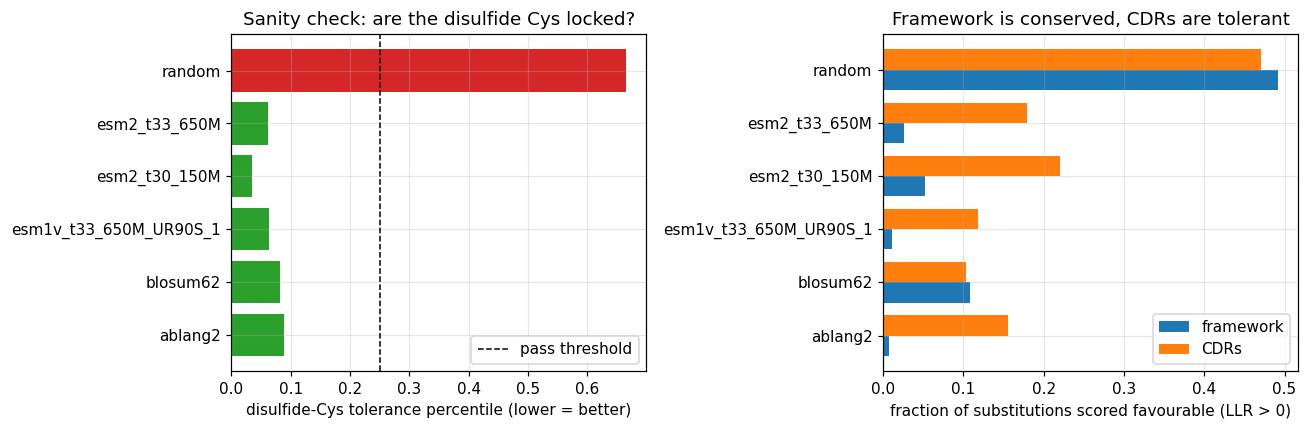

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
real = intr.drop(index=[i for i in intr.index if i.endswith('_split')])

c = ['tab:red' if v == 'FAIL' else 'tab:green' for v in real.check_cys]
ax[0].barh(real.index, real.cys_pos_pctile, color=c)
ax[0].axvline(.25, ls='--', c='k', lw=1, label='pass threshold')
ax[0].set_xlabel('disulfide-Cys tolerance percentile (lower = better)')
ax[0].set_title('Sanity check: are the disulfide Cys locked?'); ax[0].legend()

w = 0.38; y = np.arange(len(real))
ax[1].barh(y - w/2, real.frac_fav_FR,  w, label='framework')
ax[1].barh(y + w/2, real.frac_fav_CDR, w, label='CDRs')
ax[1].set_yticks(y, real.index); ax[1].legend()
ax[1].set_xlabel('fraction of substitutions scored favourable (LLR > 0)')
ax[1].set_title('Framework is conserved, CDRs are tolerant')
plt.tight_layout(); plt.show()

## 3. The key result — the models are blind to the HER2 interface

`contact_sens_auc` asks a single question, over CDR positions only:

> Does the model rate the residues that physically touch HER2 as **less** tolerant to mutation
> than the CDR residues that do not touch HER2?

AUC > 0.5 would mean yes. **Every language model scores well *below* 0.5**, while BLOSUM62 and random
sit at chance. The models are not merely uninformed about binding — they are *anti*-correlated with it.

The reason is visible in the data: trastuzumab is a **humanised mouse** antibody whose paratope was
engineered, so its HER2-contacting residues are deliberately unusual for a human antibody. The language
models, trained on natural repertoires, want to "repair" exactly those residues back to something typical.

In [5]:
cdr = info.region != 'FR'
rows = []
for m in wide:
    s = wide[m][cdr]
    rows.append({'model': m,
                 'contact CDR': s[info.contact[cdr]].mean(),
                 'non-contact CDR': s[~info.contact[cdr]].mean(),
                 'AUC': intr.loc[m, 'contact_sens_auc']})
t = pd.DataFrame(rows).set_index('model').round(3)
t['verdict'] = np.where(t.AUC < .4, 'anti-correlated with interface',
                np.where(t.AUC < .6, 'no signal (chance)', 'tracks interface'))
t

,contact CDR,non-contact CDR,AUC,verdict
model,,,,
ablang2,-1.807,-3.845,0.248,anti-correlated with interface
blosum62,-1.326,-1.373,0.481,no signal (chance)
esm1v_t33_650M_UR90S_1,-1.449,-4.425,0.178,anti-correlated with interface
esm2_t30_150M,-1.049,-2.876,0.296,anti-correlated with interface
esm2_t33_650M,-1.086,-3.165,0.261,anti-correlated with interface
esm2_t33_650M_split,-1.155,-3.135,0.267,anti-correlated with interface
random,-0.049,-0.054,0.521,no signal (chance)


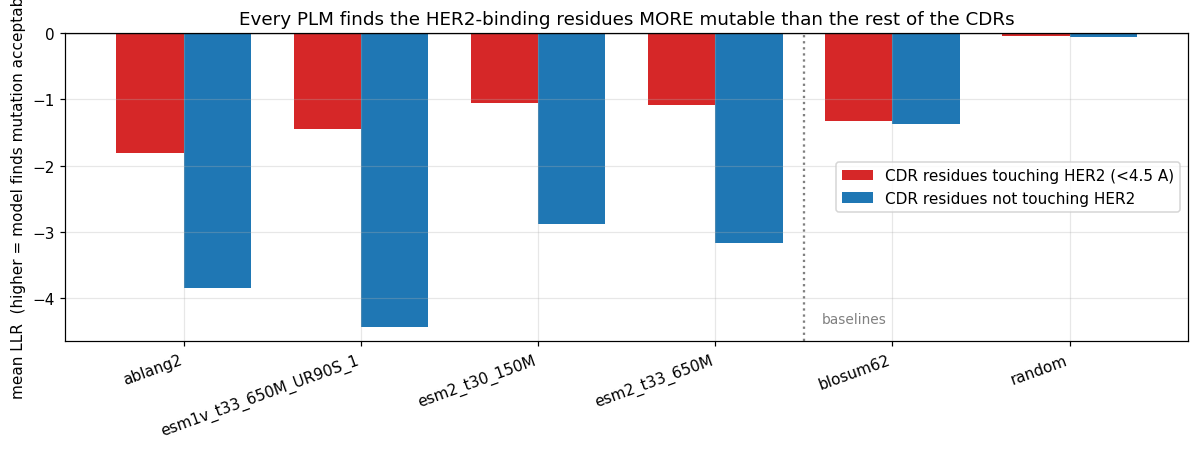

In [6]:
BASELINES = ['blosum62', 'random']
plms  = [m for m in wide if m not in BASELINES and not m.endswith('_split')]
shown = plms + BASELINES
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(shown)); w = .38
ax.bar(x - w/2, [wide[m][cdr][info.contact[cdr]].mean()  for m in shown], w,
       label='CDR residues touching HER2 (<4.5 A)', color='tab:red')
ax.bar(x + w/2, [wide[m][cdr][~info.contact[cdr]].mean() for m in shown], w,
       label='CDR residues not touching HER2', color='tab:blue')
ax.axvline(len(plms) - .5, c='grey', ls=':', lw=1.5)
ax.text(len(plms) - .4, ax.get_ylim()[0]*.95, 'baselines', fontsize=9, color='grey', va='bottom')
ax.set_xticks(x, shown, rotation=20, ha='right')
ax.set_ylabel('mean LLR  (higher = model finds mutation acceptable)')
ax.set_title('Every PLM finds the HER2-binding residues MORE mutable than the rest of the CDRs')
ax.axhline(0, c='k', lw=.8); ax.legend()
plt.tight_layout(); plt.show()

### A concrete example: VH R50

The single closest contact to HER2 in the crystal is **VH Arg50, at 2.6 Å**. AbLang2 gives the parent
arginine a probability below 1% there and would rather see Val, Ile or Leu — **its three top-scoring
mutations in the entire 4,313-mutant scan**.

The table below adds a twist worth noting: the ESM models score those same R50 substitutions *negatively*.
So at the single most important position in the paratope, the **most domain-specific model is the most
wrong**. AbLang2 is trained on natural antibody repertoires, and an arginine making a salt-bridge-like
contact in an engineered humanised paratope is precisely what such a repertoire does not contain. Being
antibody-specific buys fluency in what antibodies usually look like, not knowledge of what *this* antibody
is for.

This is why the pipeline hard-filters HER2-contact residues out of the shortlist, and why affinity gains
have to come from the structure-based stage (Boltz-2 / Mosaic / AbMPNN), not from these models.

> Everything in this section rests on crystal contact distance as a *proxy* for "matters for binding".
> **Section 6 re-runs the question against measured binding data** and revises the conclusion — the
> blindness is real for most models but not universal.

In [7]:
r50 = wide.loc[50].join(info.loc[50][['wt']]).sort_values('ablang2', ascending=False)
print('VH R50 — closest HER2 contact (2.6 A). Top substitutions each model would make:')
r50.head(5).round(2)

VH R50 — closest HER2 contact (2.6 A). Top substitutions each model would make:


,ablang2,blosum62,esm1v_t33_650M_UR90S_1,esm2_t30_150M,esm2_t33_650M,esm2_t33_650M_split,random,wt
mut,,,,,,,,
V,5.74,-3.0,0.15,-0.11,-1.93,-1.71,0.05,R
I,4.56,-3.0,-0.66,-0.82,-2.11,-1.96,-0.38,R
L,4.53,-2.0,-1.13,-1.19,-1.40,-1.20,0.59,R
F,3.57,-3.0,-0.97,-1.89,-1.74,-1.43,-1.04,R
A,3.23,-1.0,-0.59,-0.01,-1.76,-1.60,-1.38,R


## 4. Layer 2 — how much do the models agree?

If two models agree it is weak evidence that a mutation is sensible; if they agree *because they are the
same model* it is no evidence at all. So the comparison includes ESM2 at two sizes and the same ESM2
scored in two contexts.

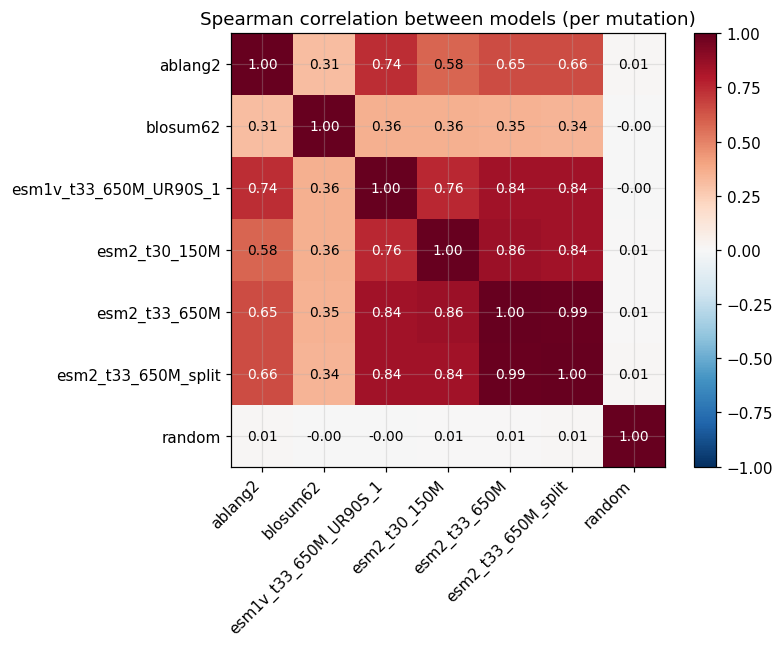

In [8]:
rho = pd.read_csv(os.path.join(EVAL, 'spearman_mutations.csv'), index_col=0)
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(rho.values, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(rho)), rho.columns, rotation=45, ha='right')
ax.set_yticks(range(len(rho)), rho.index)
for i in range(len(rho)):
    for j in range(len(rho)):
        v = rho.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                color='white' if abs(v) > .6 else 'black', fontsize=9)
ax.set_title('Spearman correlation between models (per mutation)')
plt.colorbar(im, fraction=.046); plt.tight_layout(); plt.show()

Reading the matrix:

- **ESM2-650M vs. its own split-context run: 0.99.** The linker makes no difference, so the earlier
  single-chain-vs-paired worry is settled.
- **Inside the ESM family: 0.76–0.86.** Model size shifts details, not the overall ranking.
- **AbLang2 vs. ESM2-650M: 0.65** — the antibody-specific model is the genuine outlier, which is exactly
  why it earns a place in the vote. Notably it agrees more with ESM-1v (0.74) than with ESM2-650M.
- **BLOSUM62 vs. everything: ~0.35.** The PLMs contribute much more than amino-acid similarity.
- **random vs. everything: ~0.00.** Sanity confirmed.

## 5. Consensus mutations

A mutation "gets a vote" from a model if that model ranks it in its **top 20%** *and* scores it above 0.
Only the four genuinely distinct models vote (the split run and the baselines do not).

A mutation is **eligible** only if it is not a HER2 contact, is more than 4.5 Å from HER2, is not a
cysteine substitution, does not touch a disulfide, and is not at a "suspect" position (one where the
model distrusts the parent residue itself — see §3).

In [9]:
cons = pd.read_csv(os.path.join(EVAL, 'consensus.csv'))
el = cons[cons.eligible]
print('votes distribution among eligible mutations:')
print(el.votes.value_counts().sort_index().rename('n mutations').to_frame().T.to_string())
print(f'\nunanimous (4/4): {(el.votes == 4).sum()} mutations at {el[el.votes==4].scfv_index.nunique()} positions')
el[el.votes >= 3][['mutation','region','dist','votes','mean_rank_pct']].head(20).round(3)

votes distribution among eligible mutations:
votes           0    1   2   3   4
n mutations  3092  214  60  25  11

unanimous (4/4): 11 mutations at 5 positions


,mutation,region,dist,votes,mean_rank_pct
0,D102S,H3,5.08,4,0.016
1,A106Y,H3,6.83,4,0.018
2,N28T,H1,13.25,4,0.023
3,D102G,H3,5.08,4,0.024
4,A79V,FR,13.84,4,0.028
5,T54G,H2,9.02,4,0.032
6,N28S,H1,13.25,4,0.035
7,T54D,H2,9.02,4,0.035
8,T54Y,H2,9.02,4,0.037
9,D102T,H3,5.08,4,0.041


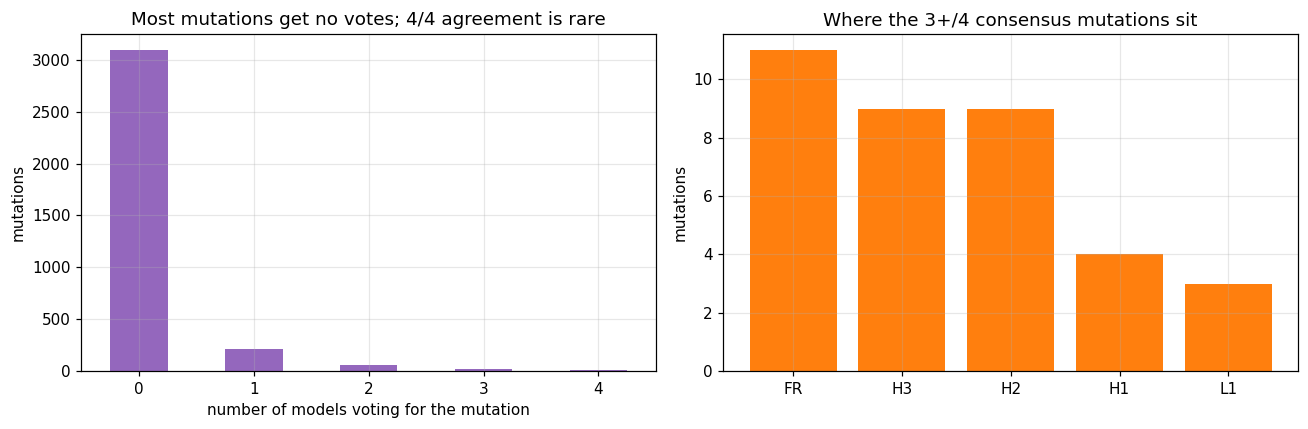

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
el.votes.value_counts().sort_index().plot.bar(ax=ax[0], color='tab:purple', rot=0)
ax[0].set_xlabel('number of models voting for the mutation'); ax[0].set_ylabel('mutations')
ax[0].set_title('Most mutations get no votes; 4/4 agreement is rare')

top = el[el.votes >= 3]
reg = top.region.value_counts()
ax[1].bar(reg.index, reg.values, color='tab:orange')
ax[1].set_title('Where the 3+/4 consensus mutations sit'); ax[1].set_ylabel('mutations')
plt.tight_layout(); plt.show()

**What the consensus is actually offering.** The unanimous mutations cluster at a handful of positions —
VH D102 (CDR-H3), VH T54 / N55 (CDR-H2), VH N28 (CDR-H1), VH A106, VH A79 (framework). Two things to note
before treating any of them as affinity candidates:

1. **Agreement is not independence.** Three of the four voters are ESM-family models correlating at
   0.76–0.86, so a 4/4 vote is closer to "two opinions agree" than to four.
2. **These are plausibility votes, not affinity predictions** — §3 applies to all of them.

One is worth singling out: **VH N55S / N55G.** The parent has an `N55-G56` pair (in `…PTNGYT…`), a classic
**deamidation liability** — a known antibody-developability problem, independent of binding. All four
models want it changed. That makes it a strong *developability* candidate on evidence these models are
actually qualified to give. It sits 5.3 Å from HER2, just outside the contact shell, so it still needs the
structure check before going into a variant.

In [11]:
seq_window = PARENT[50:60]
print('VH 51-60:', seq_window, '   (N55-G56 deamidation motif)')
n55 = cons[cons.scfv_index == 55][['mutation','votes','mean_rank_pct','dist']]
print('\nN55 substitutions by consensus:'); print(n55.head(4).round(3).to_string(index=False))

VH 51-60: IYPTNGYTRY    (N55-G56 deamidation motif)

N55 substitutions by consensus:
mutation  votes  mean_rank_pct  dist
    N55S      3          0.025  5.31
    N55G      3          0.034  5.31
    N55D      3          0.040  5.31
    N55T      3          0.040  5.31


## 6. Measured affinity — testing the models against real binding data

Everything above judged the models against a *proxy*: distance to HER2 in the crystal. That assumes
crystal contact implies mutational sensitivity — an inference, not a measurement.

The **Mason et al. trastuzumab CDR-H3 library** replaces it with real data: ~36,000 variants of the 10
residues at **scFv 99-108** (WT `WGGDGFYAMD`), sorted by yeast display into antigen-positive and
antigen-negative. That window holds 4 of our 20 HER2 contacts (W99, G103, F104, Y105) and 2 of our
consensus positions (D102, A106).

**The confound that dominates this dataset.** The library is combinatorial — median 8 mutations per
variant — and the binder rate collapses with mutation count: **0.93 at 3 mutations, 0.07 at 10**. Summed
LLRs correlate with mutation count almost by construction, so a raw AUROC rewards a model for counting
mutations rather than understanding binding. Every number below is therefore reported both overall and
**stratified by mutation count** (AUROC within each group, then averaged). Only the stratified column
answers the real question.

In [12]:
zs = pd.read_csv(os.path.join(ROOT, 'results', 'mason', 'zeroshot_auroc.csv'), index_col=0)
zs.round(3)

,n_scored,auroc_overall,auroc_stratified
model,,,
esm1v_t33_650M_UR90S_1,36367,0.727,0.637
blosum62,36367,0.567,0.562
esm2_t33_650M_split,36367,0.655,0.562
esm2_t30_150M,36367,0.626,0.556
ablang2,36367,0.678,0.541
esm2_t33_650M,36367,0.637,0.537
random,36367,0.530,0.517
baseline: fewer mutations,36368,0.774,0.500


Read the **`auroc_stratified`** column. Two checks confirm it works: the `fewer mutations` baseline drops
from 0.774 overall to exactly **0.500** stratified (it is constant within a stratum, so it must), and
`random` sits at 0.517.

**This corrects a claim made earlier in this notebook.** The contact-distance proxy suggested every PLM
was blind to binding. Against measured data that is too strong:

- **ESM-1v reaches 0.637** — modest, but clearly above BLOSUM62 (0.562) and well above chance. It carries
  genuine binding signal.
- **Every other model sits at 0.54-0.56**, at or below a substitution matrix. For those, "blind to
  affinity" survives contact with the data.
- **AbLang2, the antibody-specific model, is second worst at 0.541**, consistent with the VH R50 finding
  in section 3. Domain specificity did not help.

The accurate claim is therefore not "PLMs cannot see affinity" but **"these PLMs are weak at affinity, one
is better than the rest, and none is close to a model trained on binding data"** — which the next cell
demonstrates.

In [13]:
sup = pd.read_csv(os.path.join(ROOT, 'results', 'mason', 'supervised.csv'))
zs_only = zs.drop(index=[i for i in zs.index if 'baseline' in i or i == 'random'])
print(f'best ZERO-SHOT model (stratified AUROC): {zs_only.auroc_stratified.max():.3f}')
print()
print(sup.to_string(index=False))

best ZERO-SHOT model (stratified AUROC): 0.637

                                   model  n_train  n_test  auroc_test
            supervised: one-hot sequence    27276    9092      0.8914
supervised: one-hot, within n_mut=8 only     7172    2391      0.8386


**A one-hot logistic regression — no language model at all — reaches about 0.89**, and about 0.84 when
trained and tested inside a single mutation-count stratum so the confound cannot help it. Against about
0.64 for the best zero-shot PLM.

That gap is the argument of this section. Ten positions, 190 possible mutations and a few thousand
labelled examples beat a 650M-parameter model trained on hundreds of millions of sequences — because the
small model was trained on *the right question*. Naturalness and affinity are different objectives, and
scale on the first does not substitute for data on the second.

(With `--embeddings`, the notebook also reports an ESM2-embedding model. Embeddings retain far more than
the 1-D LLR projection, but they are still only useful once paired with labels.)

In [14]:
v = pd.read_csv(os.path.join(ROOT, 'results', 'mason', 'consensus_verdict.csv'))
v.sort_values('measured_pctile', ascending=False).round(3)

,mutation,region,dist,votes,eligible,effect,measured_pctile,n_obs,reliable
0,M107F,H3,9.36,4,False,2.082,1.00,11565,True
1,D102P,H3,5.08,0,True,1.684,0.99,2087,True
2,D102Y,H3,5.08,1,True,1.332,0.98,1837,True
3,D102F,H3,5.08,0,True,1.286,0.97,2325,True
4,D102A,H3,5.08,2,True,1.214,0.96,2099,True
...,...,...,...,...,...,...,...,...,...
185,G103K,H3,2.42,0,False,-0.036,NaN,3,False
186,G103M,H3,2.42,0,False,-0.001,NaN,1,False
187,G103C,H3,2.42,0,False,-0.338,NaN,28,False
188,Y105C,H3,3.32,0,False,-0.112,NaN,6,False


**The payoff: our own picks checked against measured binding.** Restricted to the 99 mutations observed
at least 50 times — rarer ones are shrunk toward zero by the regression and carry no information, so a
near-zero effect there means *no data*, not *no effect*. `measured_pctile` ranks within those 99.

**What we got right.** D102S, D102T and D102G — all unanimous 4/4 picks — land in the 84th–89th
percentile with 1,600–4,400 observations each. G101S (3/4) reaches the 75th. Our models' top-voted
mutations are genuinely good ones.

**What we got wrong, in three different ways:**

1. **A106T is refuted.** Three models voted for it; the data puts it in the 39th percentile across 3,968
   observations. Drop it.
2. **Our filters discarded the best mutation in the window.** `M107F` has the **highest measured effect of
   all 190 mutations** (11,565 observations) and all four models voted for it — but the `suspect_wt`
   filter removed it, because AbLang2 distrusted the parent methionine at that position. The filter was
   built to catch model artefacts; here the models were right and the filter was wrong. `M107Y` (93rd
   percentile, 3/4 votes) was lost the same way.
3. **We found the right position but the wrong substitution.** The ten best measured mutations are almost
   all at **D102** — D102P, D102Y, D102F, D102A, D102V, D102H, D102I — and most received **0–2 votes**.
   Nearly *any* substitution at D102 improves binding, which suggests the parent aspartate is simply a
   poor residue there. Our models detected the position but ranked the specific substitutions badly.

**One filter that should stay.** `D102C` measures well (91st percentile) and was filtered by our
"no mutations to cysteine" rule. That rule should stay: a free cysteine is a manufacturing and
aggregation liability that a yeast-display binding assay has no way to see. A good filter can look like a
false negative when the benchmark only measures one thing.

**Caveat on all of the above:** yeast display measures *apparent* affinity with avidity effects and is
confounded by display level, while Adaptyv runs SPR/BLI on cell-free protein. Agreement across thousands
of observations is still the best evidence available to us.

## 7. Layer 3 — performance on OUR variants (after the lab)

Layer 3 of `scripts/evaluate.py` is implemented and tested, but it needs labels:

```bash
python3 -I scripts/evaluate.py --variants results/final_15.csv                 # rules + pool scores (now)
python3 -I scripts/evaluate.py --variants labelled.csv --parent-kd 0.82        # performance (after the lab)
```

Given measured KDs it reports, per model, Spearman against −log10 KD and AUROC for "beat the 0.82 nM
parent", alongside two deliberately dumb predictors — BLOSUM62 and *"fewer mutations is better"*. A model
that cannot beat **those** has contributed nothing.

Two honest caveats:

- With **n = 15** the Spearman confidence interval is very wide. Read the *gap to the baselines*, never the
  absolute number.
- Variant scores are **additive sums of single-mutant LLRs**, so epistasis is ignored by construction.

The one way to get a real performance number *before* the lab data would be an external labelled
trastuzumab mutational dataset (e.g. the published CDR-H3 deep-mutational scan), run with `--no-rules`.
We have not downloaded one — it is the highest-value next step for this pipeline.

## 8. What this means for the 15 submitted variants

1. **These models choose the safe tier, not the bold tier.** They are competent at "still folds, still
   expresses, still looks like an antibody" and demonstrably anti-correlated with the HER2 interface. Use
   them for the ~5 safe and part of the moderate tier.
2. **Affinity has to come from the structure stage.** Boltz-2 + ipSAE ranking, AbMPNN and Mosaic are what
   can actually see the interface — and `ipSAE of the pool` is a judged criterion.
3. **Measured data settles several picks (section 6).** Use **M107F** (best measured mutation in the
   window, 4/4 votes, currently blocked only by our own `suspect_wt` filter), **D102S/T/G** (84th-89th
   percentile, unanimous) and **G101S**. **Drop A106T** — three models liked it, the data puts it in the
   39th percentile. Consider other D102 substitutions (P, Y, F, A, V) that measure even better than D102S
   but which our models under-ranked.
4. **Revisit the `suspect_wt` filter before fixing the pool.** It cost us the single best measured
   mutation. Keep the "no new cysteine" rule though — `D102C` measures well but carries a liability the
   binding assay cannot see.
5. **N55S/N55G remains the best developability pick**, a deamidation-liability fix backed by all four
   models — but it sits outside the Mason window, so it is unverified by measured data and still needs the
   structure check.
6. **Never mutate the 20 contact residues on this evidence.** The pipeline enforces it; §3 is why.
7. **Report the measured benchmark in the pitch.** "We benchmarked our own models against 36,000
   measured binders, found most of them no better than a substitution matrix, kept the mutations the data
   confirmed and dropped the one it refuted" is a far stronger story than an unexamined ranked list.

In [15]:
print('PLMs compared   :', ', '.join(plms))
print('Baselines       :', ', '.join(BASELINES))
print('Mutants scored  :', f'{len(wide):,} (all models in common)')
print('Unanimous, eligible :', int((el.votes == 4).sum()), 'mutations')
print()
print('contact_sens_auc (>0.5 = tracks the interface):')
for m in shown:
    v = intr.loc[m, 'contact_sens_auc']
    print(f'  {m:26s} {v:.3f}   {"<-- below chance" if v < .45 else ""}')

PLMs compared   : ablang2, esm1v_t33_650M_UR90S_1, esm2_t30_150M, esm2_t33_650M
Baselines       : blosum62, random
Mutants scored  : 4,313 (all models in common)
Unanimous, eligible : 11 mutations

contact_sens_auc (>0.5 = tracks the interface):
  ablang2                    0.248   <-- below chance
  esm1v_t33_650M_UR90S_1     0.178   <-- below chance
  esm2_t30_150M              0.296   <-- below chance
  esm2_t33_650M              0.261   <-- below chance
  blosum62                   0.481   
  random                     0.521   
